# Chapter 2. Object Detection 첫 실습

## 2.1 Object Detection이란?

**Object Detection(객체 탐지)**은 이미지에서 **어떤 객체가 어디에 있는지** 동시에 찾는 태스크입니다.

```
입력: 이미지
출력: 객체의 종류(클래스) + 위치(바운딩 박스)

예시:
  ┌─────────────────────────┐
  │  [사람 95%]             │
  │  ┌──────┐  [버스 87%]   │
  │  │      │  ┌─────────┐  │
  │  │      │  │         │  │
  │  └──────┘  └─────────┘  │
  └─────────────────────────┘
```

YOLO26 Detection 모델은 **COCO 데이터셋** 기준 **80가지 객체**를 탐지할 수 있습니다.

## 2.2 모델 로드

> 💡 `yolo26n.pt`(Detection 모델)을 사용합니다.

In [1]:
%matplotlib inline

In [2]:
from ultralytics import YOLO

# Detection 모델 로드
# 처음 실행 시 yolo26n.pt 가중치 파일이 자동으로 다운로드됩니다 (~5MB)
model = YOLO("yolo26n.pt")

print("모델 태스크:", model.task)   # detect
print("모델 타입:", type(model))

모델 태스크: detect
모델 타입: <class 'ultralytics.models.yolo.model.YOLO'>


## 2.3 이미지 추론

ultralytics에 내장된 `bus.jpg` 샘플 이미지로 추론합니다.

> 💡 `model(image_path)`는 **리스트**를 반환합니다. 이미지 1장을 넣어도 `results[0]`으로 첫 번째 결과를 꺼내야 합니다.  
> 이미지를 여러 장 넣으면 `results[0]`, `results[1]`, ... 식으로 각 이미지 결과를 꺼냅니다.

In [3]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")

image_path = str(ASSETS / "bus.jpg")

# 추론 실행
results = model(image_path)

print(f"탐지된 객체 수: {len(results[0].boxes)}")


image 1/1 C:\Users\SSAFY\Desktop\261030-yolo-26\books\venv\Lib\site-packages\ultralytics\assets\bus.jpg: 640x480 4 persons, 1 bus, 13.4ms
Speed: 45.3ms preprocess, 13.4ms inference, 15.3ms postprocess per image at shape (1, 3, 640, 480)
탐지된 객체 수: 5


## 2.4 결과 시각화

> 💡 **BGR vs RGB**: OpenCV는 색상을 `파랑-초록-빨강(BGR)` 순서로 저장하고, matplotlib은 `빨강-초록-파랑(RGB)` 순서를 사용합니다.  
> `result.plot()`은 OpenCV 배열(BGR)을 반환하므로, matplotlib으로 보려면 `[..., ::-1]`로 순서를 뒤집어야 합니다.
>
> 💡 **koreanize_matplotlib**: 그래프의 한국어 텍스트가 깨지지 않게 해주는 패키지입니다. matplotlib을 사용하는 모든 셀에 `import koreanize_matplotlib`을 추가합니다.

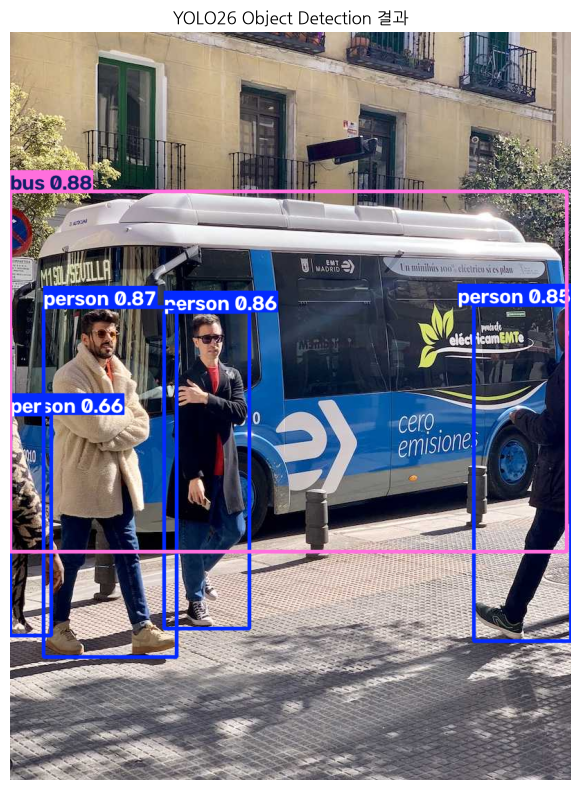

In [4]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")
image_path = str(ASSETS / "bus.jpg")

results = model(image_path, verbose=False)  # verbose=False: 추론 로그 출력 억제

# result.plot() : 바운딩 박스 + 클래스 레이블이 그려진 numpy 배열 반환 (BGR)
annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[..., ::-1])   # BGR → RGB
plt.axis("off")
plt.title("YOLO26 Object Detection 결과")
plt.tight_layout()
plt.show()

## 2.5 원본과 결과 비교

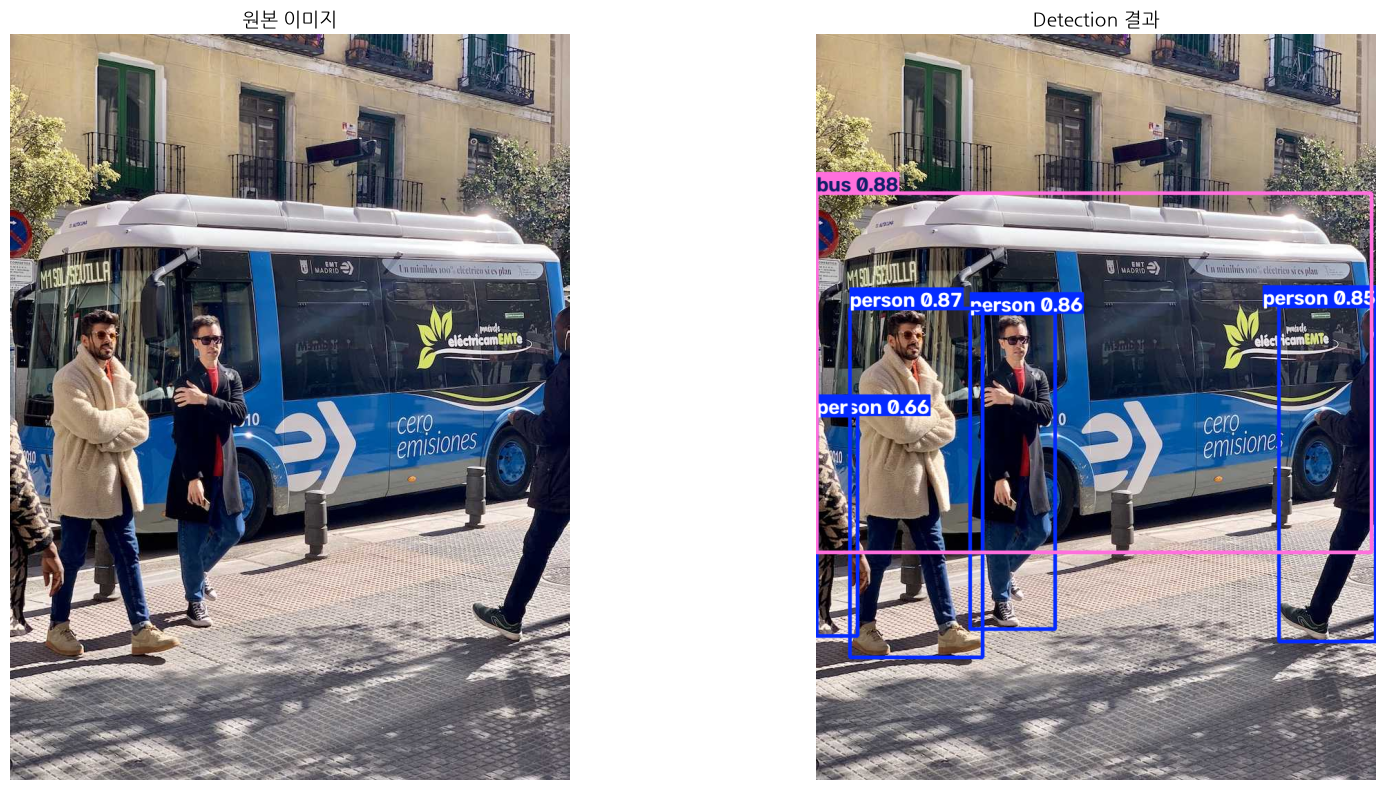

In [5]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)
result = results[0]

orig = result.orig_img[..., ::-1]       # BGR → RGB
annotated = result.plot()[..., ::-1]    # BGR → RGB

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(orig)
axes[0].set_title("원본 이미지", fontsize=14)
axes[0].axis("off")

axes[1].imshow(annotated)
axes[1].set_title("Detection 결과", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 2.6 결과를 파일로 저장

저장된 파일은 `runs/detect/predict/` 디렉터리에서 확인할 수 있습니다.

In [6]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")

# save=True로 결과 자동 저장
results = model(str(ASSETS / "bus.jpg"), save=True, verbose=False)

print("결과 저장 경로:", results[0].save_dir)

Results saved to C:\Users\SSAFY\Desktop\261030-yolo-26\books\runs\detect\predict
결과 저장 경로: C:\Users\SSAFY\Desktop\261030-yolo-26\books\runs\detect\predict


## 2.7 추론 파라미터 설정

### 주요 파라미터

| 파라미터 | 기본값 | 설명 |
|----------|--------|------|
| `conf` | 0.25 | 이 값 이상의 신뢰도인 객체만 탐지 |
| `iou` | 0.45 | 겹치는 박스를 제거하는 기준 (IOU = 두 박스가 겹치는 비율, 이 값보다 많이 겹치면 낮은 신뢰도 박스를 제거) |
| `imgsz` | 640 | 모델 내부 처리 이미지 크기. 원본 이미지는 자동으로 이 크기로 리사이즈됩니다 |
| `device` | 자동 | `"cpu"`, `"cuda:0"` 등 |
| `verbose` | True | 추론 시 로그 출력 여부 |

In [7]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")

results = model(
    str(ASSETS / "bus.jpg"),
    conf=0.5,       # 신뢰도 임계값 (기본값: 0.25)
    iou=0.45,       # IOU 임계값
    imgsz=640,      # 입력 이미지 크기
    device="cpu",   # "cpu" 또는 "cuda:0" (GPU)
    verbose=False,  # 로그 출력 여부
)

print(f"신뢰도 임계값 0.5 기준 탐지된 객체: {len(results[0].boxes)}개")

신뢰도 임계값 0.5 기준 탐지된 객체: 5개


## 2.8 여러 이미지 처리

Results saved to C:\Users\SSAFY\Desktop\261030-yolo-26\books\runs\detect\predict-2
이미지 1 (C:\Users\SSAFY\Desktop\261030-yolo-26\books\venv\Lib\site-packages\ultralytics\assets\bus.jpg): 탐지된 객체 5개
이미지 2 (C:\Users\SSAFY\Desktop\261030-yolo-26\books\venv\Lib\site-packages\ultralytics\assets\zidane.jpg): 탐지된 객체 3개
결과 저장 경로: C:\Users\SSAFY\Desktop\261030-yolo-26\books\runs\detect\predict-2


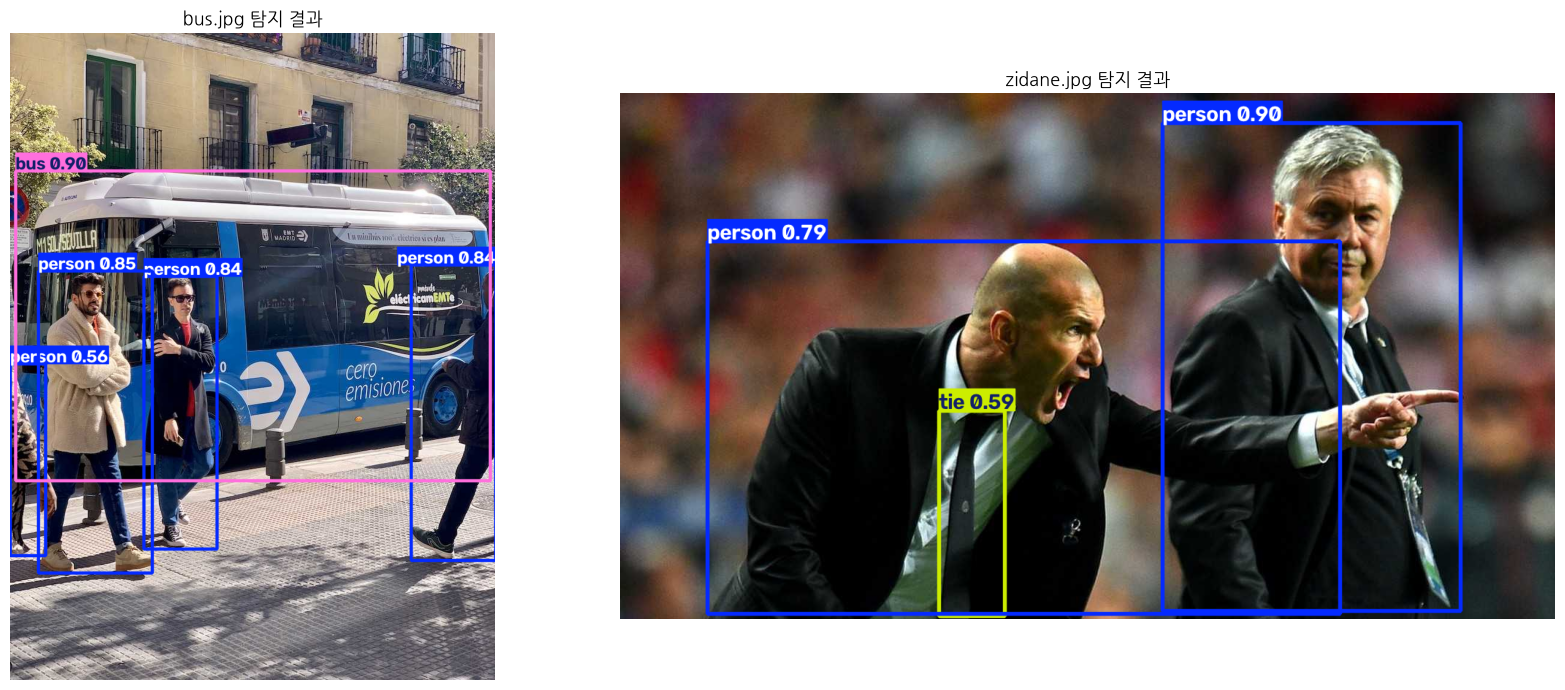

In [7]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")

image_paths = [
    str(ASSETS / "bus.jpg"),
    str(ASSETS / "zidane.jpg"),
]

# save=True 로 결과 파일 저장
results = model(image_paths, save=True, verbose=False)

# 탐지 결과 수치 출력
for i, result in enumerate(results):
    print(f"이미지 {i+1} ({image_paths[i].split('/')[-1]}): 탐지된 객체 {len(result.boxes)}개")
print("결과 저장 경로:", results[0].save_dir)

# 두 이미지 나란히 시각화
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
titles = ["bus.jpg 탐지 결과", "zidane.jpg 탐지 결과"]

for ax, result, title in zip(axes, results, titles):
    ax.imshow(result.plot()[..., ::-1])   # BGR → RGB
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.9 정리

- `YOLO("yolo26n.pt")` 로 Detection 모델을 로드합니다
- `model(image_path)` 로 추론하면 `Results` 객체 리스트가 반환됩니다
- `result.plot()` 으로 바운딩 박스가 그려진 이미지(numpy array, BGR)를 얻습니다
- `save=True` 파라미터로 결과를 파일로 저장합니다
- `conf`, `iou`, `imgsz`, `device` 파라미터로 추론을 조절합니다
